In [ ]:
!pip install discopy==1.2.2

Local verification used preinstalled DisCoPy 1.2.2. Run this installation cell in Colab.


### SMSA 19.8 — Graphical calculus for quantum information

Source: SMSA 7.8, 2026-11-05, `smsa.pdf`. References below use section and equation numbers. Read the corresponding SMSA passage first. Native DisCoPy drawings run **top to bottom**: this preview reverses SMSA’s usual vertical flow while preserving left-to-right tensor order. A coupon replaces SMSA’s specialized glyph where necessary. This notebook uses no user-defined functions or assertion checks.

Equations (19.66)–(19.67): use the native Hadamard `H` and controlled-NOT `CX`. Tensor axes are input axes followed by output axes, so flattening a gate gives a row-input array. These two SMSA matrices happen to be symmetric. The four computational-basis tests below expose the control/target order directly. The inferred diagrams implement SMSA’s displayed matrices.

In [1]:
from discopy.quantum import H, CX, Ket
print('19.66 native Hadamard entries:')
print(H.eval().array)
print('19.67 native controlled-NOT, row-input array:')
print(CX.eval().array.reshape(4, 4))
for input_bits, output_bits in [((0, 0), (0, 0)), ((0, 1), (0, 1)), ((1, 0), (1, 1)), ((1, 1), (1, 0))]:
    actual = (Ket(*input_bits) >> CX).eval()
    expected = Ket(*output_bits).eval()
    print('Input:', input_bits, '\n actual:', actual.array, '\n expected:', expected.array, '\n equal:', actual == expected)

19.66 native Hadamard entries:
[[ 0.70710678+0.j  0.70710678+0.j]
 [ 0.70710678+0.j -0.70710678+0.j]]
19.67 native controlled-NOT, row-input array:
[[1.+0.j 0.+0.j 0.+0.j 0.+0.j]
 [0.+0.j 1.+0.j 0.+0.j 0.+0.j]
 [0.+0.j 0.+0.j 0.+0.j 1.+0.j]
 [0.+0.j 0.+0.j 1.+0.j 0.+0.j]]
Input: (0, 0) 
 actual: [[1.+0.j 0.+0.j]
 [0.+0.j 0.+0.j]] 
 expected: [[1.+0.j 0.+0.j]
 [0.+0.j 0.+0.j]] 
 equal: True
Input: (0, 1) 
 actual: [[0.+0.j 1.+0.j]
 [0.+0.j 0.+0.j]] 
 expected: [[0.+0.j 1.+0.j]
 [0.+0.j 0.+0.j]] 
 equal: True
Input: (1, 0) 
 actual: [[0.+0.j 0.+0.j]
 [0.+0.j 1.+0.j]] 
 expected: [[0.+0.j 0.+0.j]
 [0.+0.j 1.+0.j]] 
 equal: True
Input: (1, 1) 
 actual: [[0.+0.j 0.+0.j]
 [1.+0.j 0.+0.j]] 
 expected: [[0.+0.j 0.+0.j]
 [1.+0.j 0.+0.j]] 
 equal: True


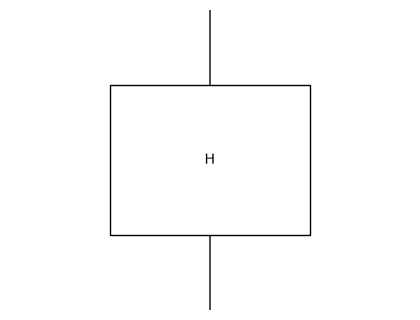

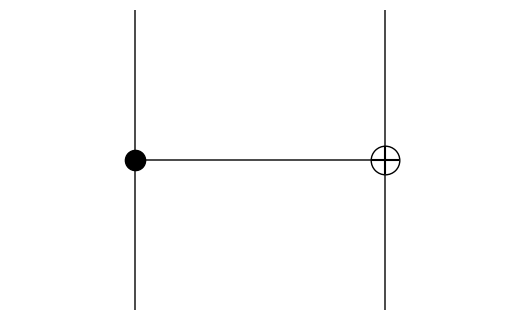

In [2]:
H.draw(figsize=(4, 3))
CX.draw(figsize=(5, 3))

### Reconstructed from the prose: the Hadamard gate exchanges the $X$ and $Z$ bases

SMSA leaves §19.8 as a list of items to be written. The two cells below are inferred from that list, not translated from drawn diagrams. The $Z$-basis is the computational basis $|0\rangle,|1\rangle$ of eigenvectors of $\sigma_z$ (the source text names $\sigma_x$ there, see `SOURCE_NOTES.md`), and the $X$-basis is $|\pm\rangle=(|0\rangle\pm|1\rangle)/\sqrt2$. The library's `X`, `Y`, `Z` are the Pauli gates; a state followed by a gate, `Ket(0) >> H`, is the gate applied to the state.

H|0> = [0.70710678+0.j 0.70710678+0.j] ; H|1> = [ 0.70710678+0.j -0.70710678+0.j]
|+> is an X eigenstate with eigenvalue 1 : True
|-> is an X eigenstate with eigenvalue -1 : True
|0> is a Z eigenstate with eigenvalue 1 : True
|1> is a Z eigenstate with eigenvalue -1 : True
H sends the X basis back to the Z basis, H|+> = |0>: True
Conjugating Z by H gives X, H Z H = X: True


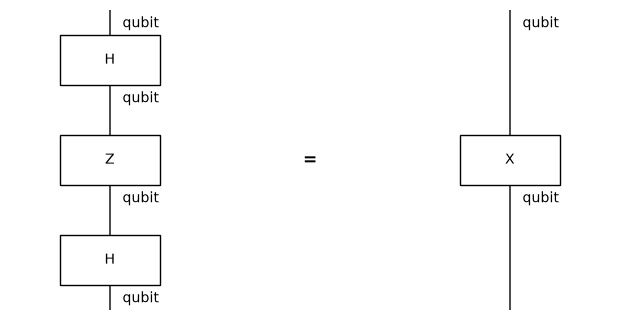

In [3]:
import numpy as np
from discopy.quantum import X, Y, Z, Id, qubit, scalar
from discopy.drawing import Equation
plus, minus = Ket(0) >> H, Ket(1) >> H
print('H|0> =', plus.eval().array, '; H|1> =', minus.eval().array)
for name, state, sign in [('|+>', plus, 1), ('|->', minus, -1)]:
    print(name, 'is an X eigenstate with eigenvalue', sign, ':', np.allclose((state >> X).eval().array, sign * state.eval().array))
for name, state, sign in [('|0>', Ket(0), 1), ('|1>', Ket(1), -1)]:
    print(name, 'is a Z eigenstate with eigenvalue', sign, ':', np.allclose((state >> Z).eval().array, sign * state.eval().array))
print('H sends the X basis back to the Z basis, H|+> = |0>:', np.allclose((plus >> H).eval().array, Ket(0).eval().array))
print('Conjugating Z by H gives X, H Z H = X:', np.allclose((H >> Z >> H).eval().array, X.eval().array))
Equation(H >> Z >> H, X, symbol='=').draw(figsize=(6, 3))


**Pauli products span the maps between qubit registers.** The four matrices $1,\sigma_x,\sigma_y,\sigma_z$ are orthogonal for the trace pairing, $\mathrm{tr}(\sigma_a\sigma_b)=2\delta_{ab}$, so they are a basis of the $2\times2$ matrices, and their tensor products are a basis of the maps on $n$ qubits. The cell decomposes the CNOT gate of (19.67) as $\tfrac12(1\otimes1+\sigma_z\otimes1+1\otimes\sigma_x-\sigma_z\otimes\sigma_x)$, first by computing the sixteen coefficients $\tfrac14\mathrm{tr}\big((\sigma_a\otimes\sigma_b)^\dagger\,\mathrm{CNOT}\big)$ and then by adding the four native circuits. Arrays are printed with the input axis first, so the printed `Y` is the transpose of the usual matrix.

Native Y array, input axis first, the transpose of [[0,-i],[i,0]]:
 [[ 0.+0.j  0.+1.j]
 [-0.-1.j  0.+0.j]]
tr(sigma_a sigma_b), rows and columns I,X,Y,Z:
 [[2. 0. 0. 0.]
 [0. 2. 0. 0.]
 [0. 0. 2. 0.]
 [0. 0. 0. 2.]]
Equals 2 times the identity, so the four Paulis are a basis of the 2x2 matrices: True
Nonzero coefficients of CNOT on sigma_a ⊗ sigma_b: {'II': 0.5, 'IX': 0.5, 'ZI': 0.5, 'ZX': -0.5}
Sum of the sixteen terms equals CNOT: True
Native sum of four circuits, row-input array:
 [[1. 0. 0. 0.]
 [0. 1. 0. 0.]
 [0. 0. 0. 1.]
 [0. 0. 1. 0.]]
Equals the CNOT array: True


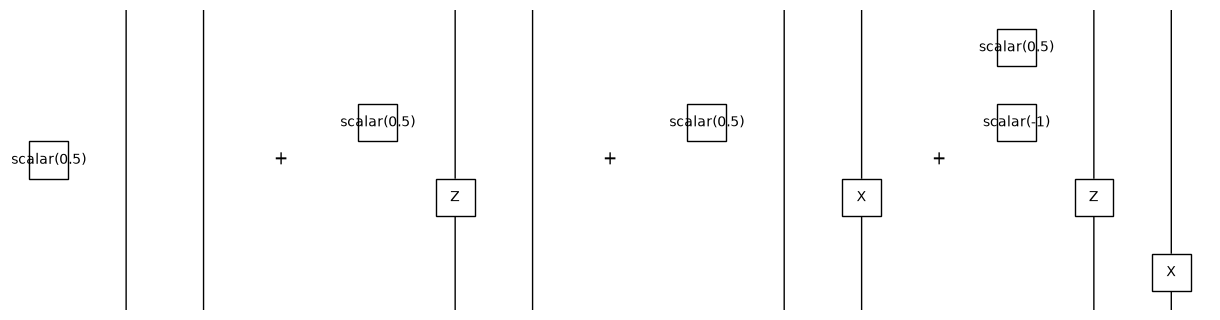

In [4]:
paulis = {'I': Id(qubit), 'X': X, 'Y': Y, 'Z': Z}
print('Native Y array, input axis first, the transpose of [[0,-i],[i,0]]:\n', Y.eval().array)
gram = np.array([[np.trace(paulis[a].eval().array @ paulis[b].eval().array) for b in 'IXYZ'] for a in 'IXYZ'])
print('tr(sigma_a sigma_b), rows and columns I,X,Y,Z:\n', np.round(gram.real, 12))
print('Equals 2 times the identity, so the four Paulis are a basis of the 2x2 matrices:', np.allclose(gram, 2 * np.eye(4)))
cnot = CX.eval().array.reshape(4, 4)
coefficients = {a + b: np.trace((paulis[a] @ paulis[b]).eval().array.reshape(4, 4).conj().T @ cnot) / 4 for a in 'IXYZ' for b in 'IXYZ'}
print('Nonzero coefficients of CNOT on sigma_a ⊗ sigma_b:', {k: float(np.round(v.real, 12)) for k, v in coefficients.items() if abs(v) > 1e-12})
rebuilt = sum(coefficients[a + b] * (paulis[a] @ paulis[b]).eval().array.reshape(4, 4) for a in 'IXYZ' for b in 'IXYZ')
print('Sum of the sixteen terms equals CNOT:', np.allclose(rebuilt, cnot))
native_sum = scalar(0.5) @ (Id(qubit @ qubit) + (Z @ Id(qubit)) + (Id(qubit) @ X) + (scalar(-1) @ (Z @ X)))
print('Native sum of four circuits, row-input array:\n', np.round(native_sum.eval().array.reshape(4, 4).real, 12))
print('Equals the CNOT array:', np.allclose(native_sum.eval().array, CX.eval().array))
native_sum.draw(figsize=(12, 3))


**Scope.** The basis statements are checked on the four states and the sixteen coefficients shown. SMSA's further items for this section (Frobenius structures on qubits, more gates) are not reconstructed; the explicit matrices and the computational bit order fix the conventions used here.